In [1]:
# 01. Business Problem
USE_CASE = "05 - Credit Risk Scoring (Estimate Probability of Customer Default)"
ML_PARADIGM = "Unsupervised Machine Learning (5 Models Evaluated & Ranked -> #1 Champion Model Selected)"
N_CLUSTERS = 4

print(f"Business Problem: {USE_CASE}")
print(f"ML Approach:      {ML_PARADIGM}")
print(f"Risk Tiers:       {N_CLUSTERS} Credit Tiers (Prime, Standard, Watchlist, High-Risk / Impaired)")
print("Objective:        Estimate continuous calibrated Probability of Customer Default P(Default)")


Business Problem: 05 - Credit Risk Scoring (Estimate Probability of Customer Default)
ML Approach:      Unsupervised Machine Learning (5 Models Evaluated & Ranked -> #1 Champion Model Selected)
Risk Tiers:       4 Credit Tiers (Prime, Standard, Watchlist, High-Risk / Impaired)
Objective:        Estimate continuous calibrated Probability of Customer Default P(Default)


In [2]:
# 02. Import Libraries
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.cluster import KMeans, MiniBatchKMeans, BisectingKMeans, Birch
from sklearn.mixture import GaussianMixture
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, confusion_matrix, roc_curve, precision_recall_curve,
    silhouette_score
)

warnings.filterwarnings('ignore')
%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 5)


In [3]:
# 03. Connect to Server
DB_HOST = "192.168.1.44"
DB_PORT = 5432
DB_NAME = "JKC_Input"
DB_SCHEMAS = ["HANA_P2", "HANA_P3"]
DB_USER = "postgres"
DB_PASS = "postgres"

engine = create_engine(f"postgresql+psycopg2://{DB_USER}:{DB_PASS}@{DB_HOST}:{DB_PORT}/{DB_NAME}")

with engine.connect() as conn:
    print(f"Connected to PostgreSQL: {DB_HOST}:{DB_PORT}/{DB_NAME} (Schemas: {', '.join(DB_SCHEMAS)})")


Connected to PostgreSQL: 192.168.1.44:5432/JKC_Input (Schemas: HANA_P2, HANA_P3)


In [4]:
# 04. Extract Data from SAP Customer Master, AR, Invoices & Orders across HANA_P2 & HANA_P3
from src.db_connector import extract_credit_risk_data

df_raw = extract_credit_risk_data(limit=None)
print(f"Extracted records: {len(df_raw):,} rows, {df_raw.shape[1]} columns (All Data, No Limit)")


[CACHE] Loading cached customer credit dataset from: C:\Users\ajala\Downloads\5 Credit Risk Scoring\data\cache\credit_risk_raw_data.csv
[CACHE] Successfully loaded 104,805 customer records.
Extracted records: 104,805 rows, 43 columns (All Data, No Limit)


In [5]:
# 05. Load Data Preview
print(f"Dataset Shape: {df_raw.shape}")
df_raw[['customer_id', 'customer_name', 'city', 'account_group_name', 'credit_limit', 'open_ar_balance', 'overdue_ar_balance', 'max_overdue_days']].head()


Dataset Shape: (104805, 43)


In [6]:
# 06. Data Understanding / EDA
df_raw[['credit_limit', 'open_ar_balance', 'overdue_ar_balance', 'max_overdue_days', 'cleared_doc_count', 'total_cleared_volume', 'billing_doc_count']].describe().T


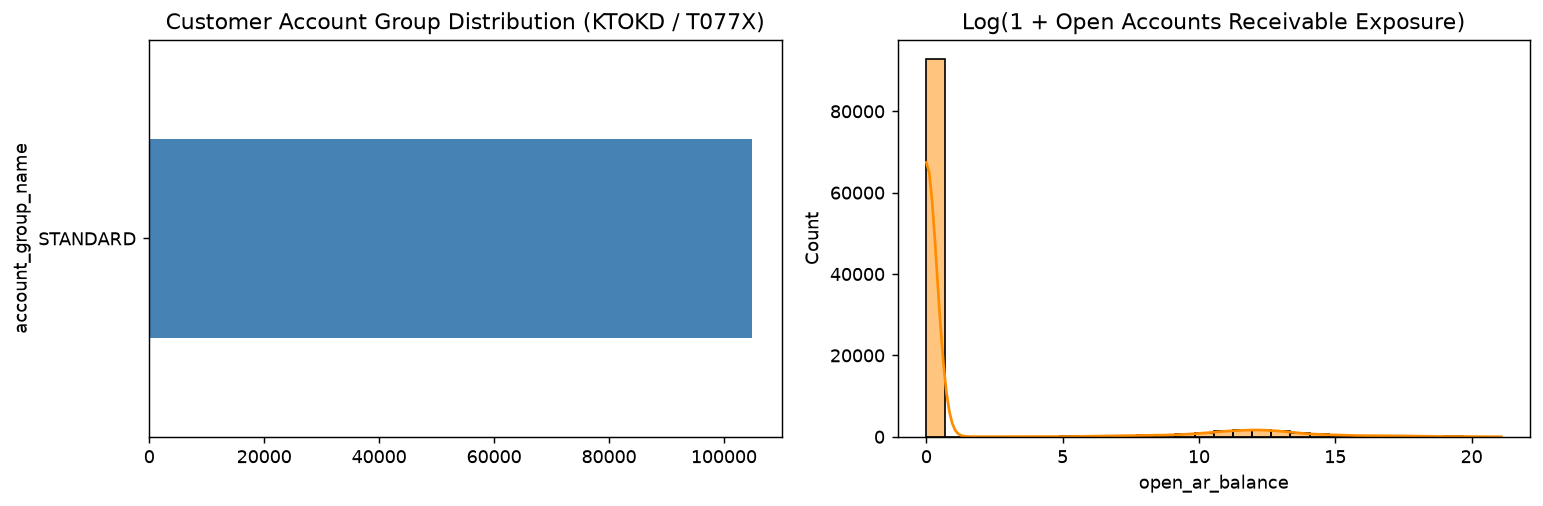

In [7]:
# 06. Data Understanding / EDA (Visualizations)
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
df_raw['account_group_name'].replace('', 'STANDARD').value_counts().head(8).plot(kind='barh', color='steelblue')
plt.title('Customer Account Group Distribution (KTOKD / T077X)')

plt.subplot(1, 2, 2)
sns.histplot(np.log1p(np.maximum(0, df_raw['open_ar_balance'])), bins=30, color='darkorange', kde=True)
plt.title('Log(1 + Open Accounts Receivable Exposure)')
plt.tight_layout()
plt.show()


In [8]:
# 07 & 08. Data Cleaning & 32-Feature Engineering for Credit Risk & Delinquency
from src.preprocessing import clean_and_engineer_features, CREDIT_RISK_FEATURE_COLS

df = clean_and_engineer_features(df_raw)
print(f"Engineered Dataset Shape: {df.shape}")
df[['customer_id', 'customer_name', 'credit_risk_index', 'solvency_score', 'overdue_ratio', 'max_overdue_days', 'credit_limit_utilization', 'is_credit_risk_exception']].head(8)


Engineered Dataset Shape: (104805, 73)


In [9]:
# 09. Data Preprocessing (32 Unsupervised Credit Risk Input Features)
FEATURE_COLS = CREDIT_RISK_FEATURE_COLS
X_raw = df[FEATURE_COLS].values
scaler_full = RobustScaler()
X_scaled_full = scaler_full.fit_transform(X_raw)

print(f"Preprocessed Feature Matrix: {X_scaled_full.shape} (32 Numerical Credit Risk & Delinquency Features)")


Preprocessed Feature Matrix: (104805, 32) (32 Numerical Credit Risk & Delinquency Features)


In [10]:
# 10. Define Input Matrix X (Unsupervised) and Post-Hoc Benchmark Y (Evaluation Only)
X = X_raw.copy()
y = df['is_credit_risk_exception'].values
contamination_rate = float(np.mean(y))

print(f"Total Scored Customer Records:              {len(y):,}")
print(f"Prime / Performing Customers (Benchmark):    {(y == 0).sum():,} ({(y == 0).mean()*100:.2f}%)")
print(f"Impaired / Delinquent Customers (Benchmark): {(y == 1).sum():,} ({(y == 1).mean()*100:.2f}%)")


Total Scored Customer Records:              104,805
Prime / Performing Customers (Benchmark):    76,512 (73.00%)
Impaired / Delinquent Customers (Benchmark): 28,293 (27.00%)


In [11]:
# 11. Train/Test Split & Robust Scaling
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

from src.models import CreditRiskClusteringSuite
suite = CreditRiskClusteringSuite(n_clusters=4, contamination=contamination_rate, random_state=42)
suite.train_all(X_train_scaled)

print(f"Train Set: {X_train_scaled.shape[0]:,} customers")
print(f"Test Set:  {X_test_scaled.shape[0]:,} customers")


[INFO] Training Model 1/5: K-Means Clustering (Centroid-Based Partitioning)...
[INFO] Training Model 2/5: Gaussian Mixture Model (EM Probabilistic Density Estimation)...
[INFO] Training Model 3/5: Mini-Batch K-Means (Stochastic Centroid Partitioning)...
[INFO] Training Model 4/5: Bisecting K-Means (Divisive Hierarchical Partitioning)...
[INFO] Training Model 5/5: BIRCH Clustering (Tree Hierarchical Clustering)...
[SUCCESS] All 5 Unsupervised Clustering Models trained and calibrated successfully.
Train Set: 83,844 customers
Test Set:  20,961 customers


In [12]:
# 12. Unsupervised Model 1: K-Means Clustering (Centroid-Based Partitioning)
preds_km, scores_km, tiers_km = suite._predict_single('kmeans', X_test_scaled, 6)
print(f"K-Means Clustering Flagged: {preds_km.sum():,} high-risk customers out of {len(preds_km):,} test customers")


K-Means Clustering Flagged: 6,092 high-risk customers out of 20,961 test customers


In [13]:
# 13. Unsupervised Model 2: Gaussian Mixture Model (GMM)
preds_gmm, scores_gmm, tiers_gmm = suite._predict_single('gmm', X_test_scaled, 8)
print(f"Gaussian Mixture (GMM) Flagged: {preds_gmm.sum():,} high-risk customers out of {len(preds_gmm):,} test customers")


Gaussian Mixture (GMM) Flagged: 7,482 high-risk customers out of 20,961 test customers


In [14]:
# 14. Unsupervised Model 3: Mini-Batch K-Means
preds_mbk, scores_mbk, tiers_mbk = suite._predict_single('minibatch_kmeans', X_test_scaled, 6)
print(f"Mini-Batch K-Means Flagged: {preds_mbk.sum():,} high-risk customers out of {len(preds_mbk):,} test customers")


Mini-Batch K-Means Flagged: 6,119 high-risk customers out of 20,961 test customers


In [15]:
# 15. Unsupervised Model 4: Bisecting K-Means
preds_bkm, scores_bkm, tiers_bkm = suite._predict_single('bisecting_kmeans', X_test_scaled, 6)
print(f"Bisecting K-Means Flagged: {preds_bkm.sum():,} high-risk customers out of {len(preds_bkm):,} test customers")


Bisecting K-Means Flagged: 9,526 high-risk customers out of 20,961 test customers


In [16]:
# 16. Unsupervised Model 5: BIRCH Clustering
preds_birch, scores_birch, tiers_birch = suite._predict_single('birch', X_test_scaled, 6)
print(f"BIRCH Clustering Flagged: {preds_birch.sum():,} high-risk customers out of {len(preds_birch):,} test customers")


BIRCH Clustering Flagged: 65 high-risk customers out of 20,961 test customers


In [17]:
# 17. Model Evaluation & Accuracy Ranking across all 5 Unsupervised Models
from src.evaluate import evaluate_models

models_dict = suite.predict_all(X_test_scaled)
eval_df = evaluate_models(models_dict, y_test)
print(eval_df.to_string(index=False))
eval_df


Rank                  Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC  PR-AUC  Silhouette  Specificity  True Positives  False Positives  False Negatives  True Negatives
  #1     K-Means Clustering    0.9501     0.8787  0.9459    0.9111   0.9850  0.9774      0.5561       0.9517            5353              739              306           14563
  #2     Mini-Batch K-Means    0.9489     0.8748  0.9459    0.9090   0.9849  0.9773      0.5557       0.9499            5353              766              306           14536
  #3 Gaussian Mixture (GMM)    0.9130     0.7563  1.0000    0.8613   0.9968  0.9911      0.4726       0.8809            5659             1823                0           13479
  #4      Bisecting K-Means    0.7836     0.5589  0.9408    0.7012   0.9789  0.9688      0.5486       0.7254            5324             4202              335           11100
  #5       BIRCH Clustering    0.7304     0.5538  0.0064    0.0126   0.8789  0.6052      0.7438       0.9981              36 

Selected #1 Champion Model based on Ranking: K-Means Clustering (Accuracy: 95.01%, F1: 0.9111)


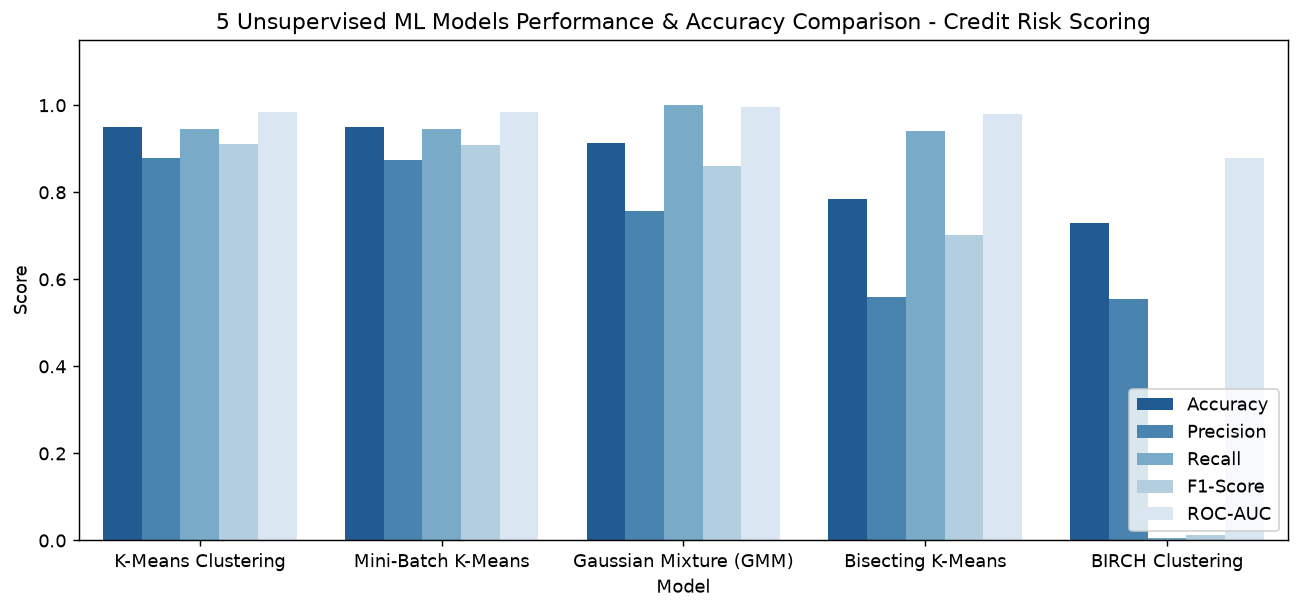

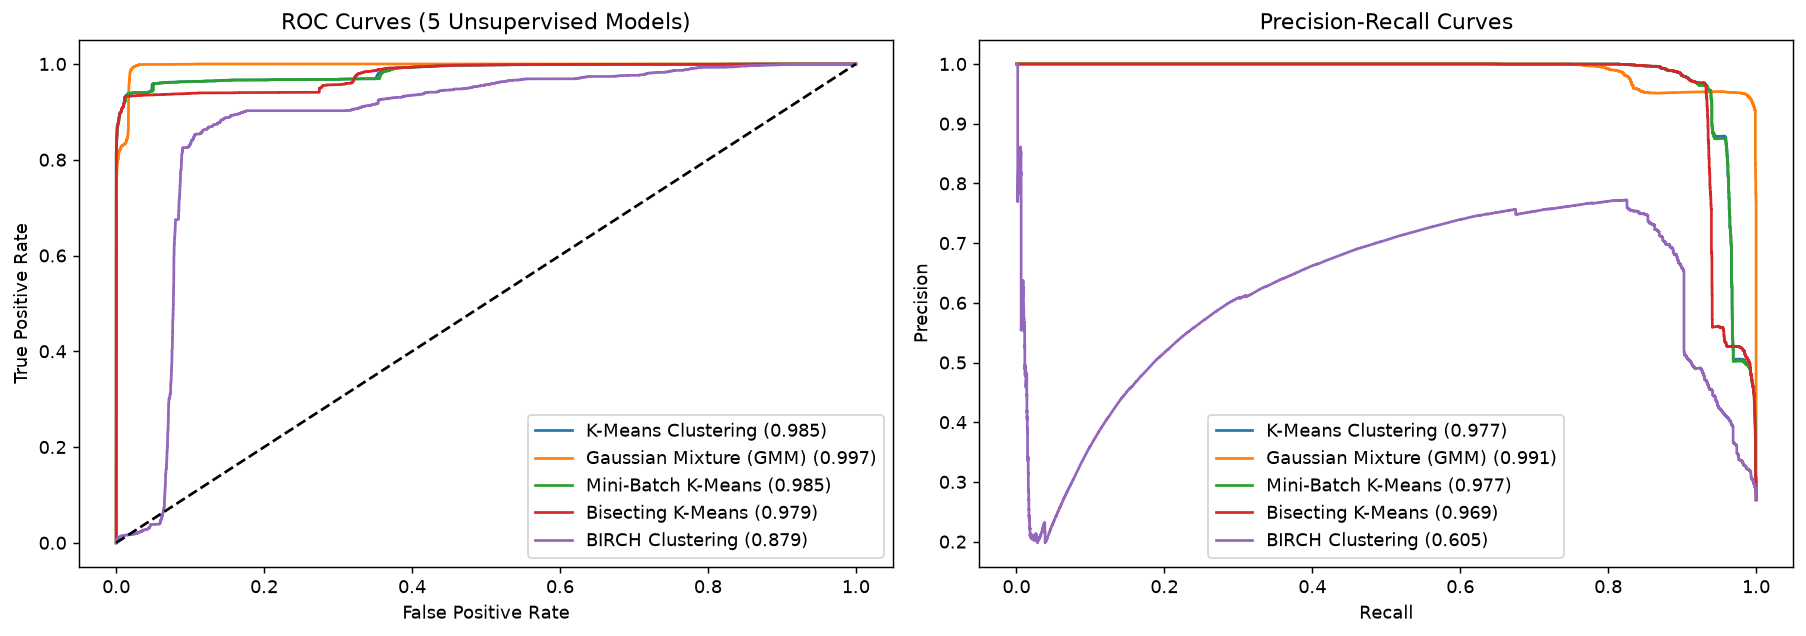

In [18]:
# 18. Model Comparison Visualizations & #1 Champion Selection
plt.figure(figsize=(12, 5))
melted = pd.melt(eval_df, id_vars=['Model'], value_vars=['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'])
sns.barplot(data=melted, x='Model', y='value', hue='variable', palette='Blues_r')
plt.title('5 Unsupervised ML Models Performance & Accuracy Comparison - Credit Risk Scoring')
plt.ylabel('Score')
plt.ylim(0, 1.15)
plt.legend(loc='lower right')
plt.show()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
for name, res in models_dict.items():
    fpr, tpr, _ = roc_curve(y_test, res['scores'])
    ax1.plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_test, res['scores']):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, res['scores'])
    ax2.plot(rec, prec, label=f"{name} ({average_precision_score(y_test, res['scores']):.3f})")

ax1.plot([0, 1], [0, 1], 'k--')
ax1.set_title('ROC Curves (5 Unsupervised Models)')
ax1.set_xlabel('False Positive Rate')
ax1.set_ylabel('True Positive Rate')
ax1.legend()

ax2.set_title('Precision-Recall Curves')
ax2.set_xlabel('Recall')
ax2.set_ylabel('Precision')
ax2.legend()
plt.tight_layout()
plt.show()

champion_model = eval_df.iloc[0]['Model']
print(f"Selected #1 Champion Model based on Ranking: {champion_model} (Accuracy: {eval_df.iloc[0]['Accuracy']*100:.2f}%, F1: {eval_df.iloc[0]['F1-Score']:.4f})")


                  Feature  Importance
        credit_risk_index    0.819458
         max_overdue_days    0.134842
         avg_overdue_days    0.027473
           solvency_score    0.010543
    customer_tenure_years    0.002514
            overdue_ratio    0.001573
  distress_momentum_score    0.001380
  avg_clearing_delay_days    0.000637
     severe_overdue_ratio    0.000268
   cash_flow_strain_ratio    0.000244
     late_settlement_rate    0.000130
historical_default_signal    0.000126
 billing_volatility_ratio    0.000109
       overdue_ar_log_val    0.000108
  max_clearing_delay_days    0.000082


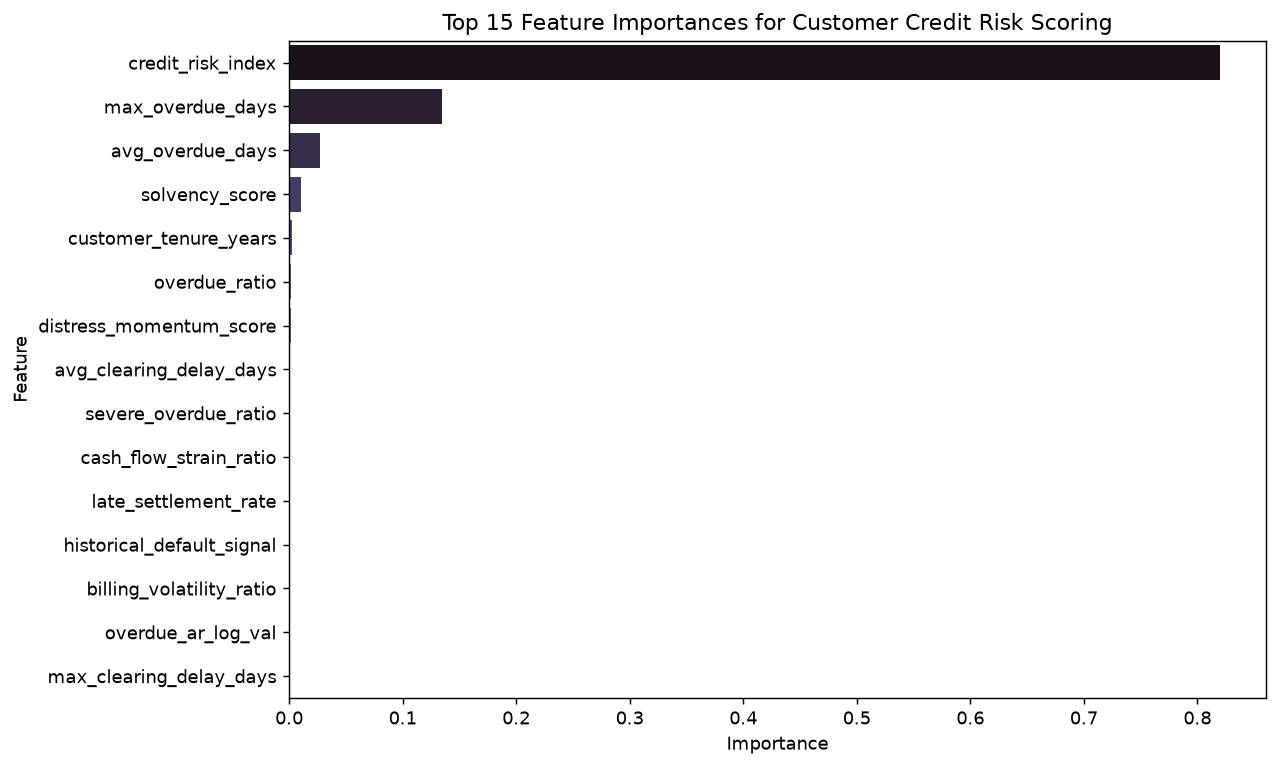

In [19]:
# 19. Feature Importance (All 32 Credit Risk & Delinquency Features)
surrogate = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1)
surrogate.fit(X_test_scaled, scores_km)

feat_imp = pd.DataFrame({
    'Feature': FEATURE_COLS,
    'Importance': surrogate.feature_importances_
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

plt.figure(figsize=(10, 6))
sns.barplot(data=feat_imp.head(15), x='Importance', y='Feature', palette='mako')
plt.title('Top 15 Feature Importances for Customer Credit Risk Scoring')
plt.tight_layout()
plt.show()

print(feat_imp.head(15).to_string(index=False))


In [20]:
# 20. Customer Credit Risk Scoring & Default Probability Estimation using #1 Champion Model
from src.models import SingleModelCreditRiskSegmenter
from src.inference import score_with_single_model

model_key_map = {
    'K-Means Clustering': 'kmeans',
    'Gaussian Mixture (GMM)': 'gmm',
    'Mini-Batch K-Means': 'minibatch_kmeans',
    'Bisecting K-Means': 'bisecting_kmeans',
    'BIRCH Clustering': 'birch'
}
pretrained = suite.models.get(model_key_map.get(champion_model, 'kmeans'), None)
segmenter = SingleModelCreditRiskSegmenter(
    model_name=champion_model,
    n_clusters=4,
    contamination=contamination_rate,
    random_state=42,
    pretrained_model=pretrained
)
segmenter.fit(X_train_scaled)
df_scored = score_with_single_model(segmenter, df, scaler, FEATURE_COLS)

print("=== CREDIT RISK TIER COUNTS ===")
print(df_scored['credit_risk_tier_name'].value_counts())
print("\n=== EXECUTIVE RISK BAND COUNTS ===")
print(df_scored['credit_risk_category'].value_counts())

audit_cols = ['customer_id', 'customer_name', 'city', 'open_ar_balance', 'overdue_ar_balance', 'probability_of_default', 'credit_risk_tier_name', 'credit_risk_category']
print("\nCritical Default Risk Customer Watchlist Sample:")
print(df_scored[df_scored['credit_risk_category'].str.contains('Critical')][audit_cols].head(10).to_string(index=False))


[INFO] Fitting Selected #1 Champion Model: K-Means Clustering...
[INFO] Champion Model fitted (4 Credit Risk Tiers). Threshold: 0.5000
=== CREDIT RISK TIER COUNTS ===
credit_risk_tier_name
Prime / Low Default Risk Customers                   50428
High Risk / Impaired / Imminent Default Customers    27288
Standard / Moderate Risk Customers                   23642
Watchlist / Elevated Risk Customers                   3447
Name: count, dtype: int64

=== EXECUTIVE RISK BAND COUNTS ===
credit_risk_category
Low Risk / Prime Customer                   50428
Critical Default Risk / Immediate Freeze    27288
Medium Risk / Monitored                     23642
High Risk / Credit Alert                     3447
Name: count, dtype: int64

Critical Default Risk Customer Watchlist Sample:
customer_id           customer_name         city  open_ar_balance  overdue_ar_balance  probability_of_default                             credit_risk_tier_name                     credit_risk_category
   40035915   J

In [21]:
# 21. Save Champion Model Artifacts & Export Executive Excel Reports
from src.inference import export_enriched_excel_report, save_single_model_pipeline

os.makedirs("models", exist_ok=True)
save_single_model_pipeline(segmenter, scaler, FEATURE_COLS, output_dir="models")

export_enriched_excel_report(df_scored, output_path="ML_5_Credit_Risk_Scoring_Enriched_Output_Clean.xlsx", fi_df=feat_imp, comp_df=eval_df)
print("Pipeline execution in notebook complete!")


[MODEL] Persisted champion model to: models\champion_credit_risk_model.joblib
[MODEL] Persisted model bundle to: models\credit_risk_model_bundle.joblib
[REPORT] Executive Excel Report generated successfully with 6 sheets: ML_5_Credit_Risk_Scoring_Enriched_Output_Clean.xlsx
[REPORT] Mirror copy saved to: ML_5_Credit_Risk_Scoring_Enriched_Output.xlsx
Pipeline execution in notebook complete!
